In [15]:
!pip -q install xgboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from IPython.display import display

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [16]:
uploaded = files.upload()
if not uploaded:
    raise ValueError("/content/bank.csv.")

file_name = next(iter(uploaded))
df = pd.read_csv(file_name, sep=None, engine="python")
df.columns = df.columns.astype(str).str.strip()

# Remove accidental spaces around text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Loaded file:", file_name)
print("Dataset shape:", df.shape)
display(df.head())

Saving bank.csv to bank (2).csv
Loaded file: bank (2).csv
Dataset shape: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [17]:
target_candidates = ["y", "deposit", "target", "subscribed"]
target_col = next((c for c in target_candidates if c in df.columns.str.lower()), None)

# Match target column ignoring capitalization
if target_col is not None:
    target_col = next(c for c in df.columns if c.lower() == target_col)

if target_col is None:
    raise ValueError(
        "Target column not found. Expected one of: y, deposit, target, subscribed. "
        "Make sure you uploaded the training/full CSV, not an unlabeled test CSV."
    )

print("Target column:", target_col)
print("Rows and columns:", df.shape)
print("\nColumn data types:")
display(df.dtypes.to_frame("data_type"))
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df[target_col].value_counts(dropna=False).to_frame("count"))

Target column: y
Rows and columns: (4521, 17)

Column data types:


,data_type
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Missing values:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Duplicate rows: 0

Target distribution:


,count
y,
no,4000
yes,521


In [18]:
# Remove exact duplicate rows
before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {before - len(df)} duplicate rows.")

# Standardize target labels
raw_y = df[target_col]
if raw_y.dtype == "object":
    normalized = raw_y.astype(str).str.strip().str.lower()
    mapping = {"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0}
    y = normalized.map(mapping)
else:
    y = pd.to_numeric(raw_y, errors="coerce")

valid = y.notna()
df = df.loc[valid].copy()
y = y.loc[valid].astype(int)

if y.nunique() != 2:
    raise ValueError(f"Expected a binary target, but found values: {sorted(y.unique())}")

X = df.drop(columns=[target_col])

# Remove post-call duration to avoid leakage in realistic pre-call prediction
duration_cols = [c for c in X.columns if c.lower() == "duration"]
if duration_cols:
    X = X.drop(columns=duration_cols)
    print("Excluded duration feature to prevent target leakage.")

# Remove common identifier columns (IDs do not describe customer behaviour)
id_cols = [c for c in X.columns if c.lower() in ["id", "customer_id", "recordid"]]
if id_cols:
    X = X.drop(columns=id_cols)
    print("Excluded identifier columns:", id_cols)

print("Feature matrix:", X.shape)
print("Target balance:")
display(y.value_counts(normalize=True).rename("proportion").to_frame())

Removed 0 duplicate rows.
Excluded duration feature to prevent target leakage.
Feature matrix: (4521, 15)
Target balance:


,proportion
y,
0,0.88476
1,0.11524


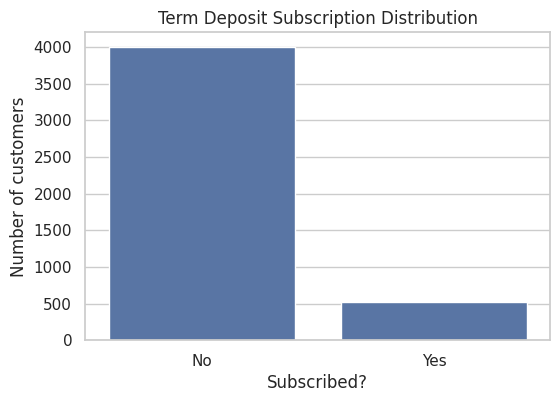

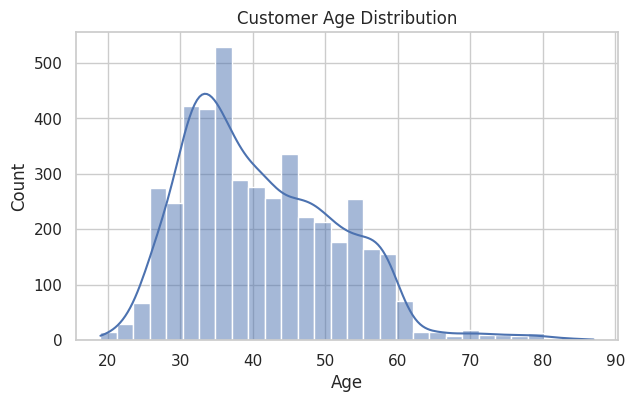

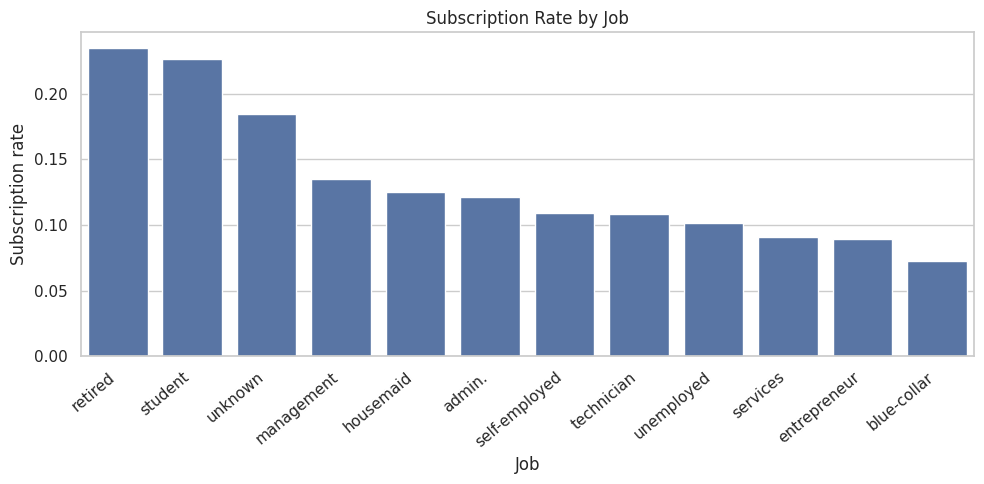

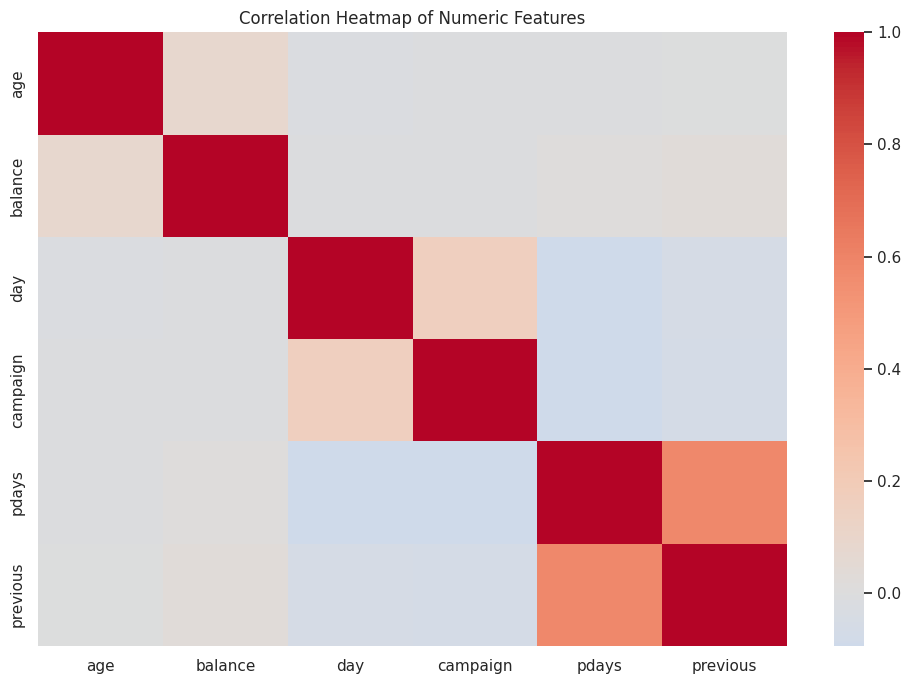

In [19]:
# Visualization 1: Target class distribution
plt.figure(figsize=(6,4))
sns.countplot(x=y.map({0:"No", 1:"Yes"}), order=["No","Yes"])
plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscribed?")
plt.ylabel("Number of customers")
plt.show()

# Visualization 2: Age distribution, if available
age_col = next((c for c in X.columns if c.lower() == "age"), None)
if age_col:
    plt.figure(figsize=(7,4))
    sns.histplot(data=X, x=age_col, bins=30, kde=True)
    plt.title("Customer Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.show()
else:
    print("Age column not found; skip age histogram.")

# Visualization 3: Subscription rate by job, if available
job_col = next((c for c in X.columns if c.lower() == "job"), None)
if job_col:
    plot_df = pd.DataFrame({job_col: X[job_col].astype(str), "subscribed": y.values})
    rates = plot_df.groupby(job_col)["subscribed"].mean().sort_values(ascending=False)
    plt.figure(figsize=(10,5))
    sns.barplot(x=rates.index, y=rates.values)
    plt.title("Subscription Rate by Job")
    plt.xlabel("Job")
    plt.ylabel("Subscription rate")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Job column not found; skip job chart.")

# Visualization 4: Correlation heatmap for numeric columns
numeric_for_corr = X.select_dtypes(include=np.number)
if numeric_for_corr.shape[1] >= 2:
    plt.figure(figsize=(10,7))
    sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap of Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 3616
Testing rows: 905
Numerical features: 6
Categorical features: 9


In [21]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        n_estimators=120, learning_rate=0.5, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=120, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=180, max_depth=3, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

pipelines = {}
results = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba)
    }
    results.append(row)
    pipelines[name] = pipe
    print(name, "trained.")

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.round(4))

Decision Tree trained.
AdaBoost trained.
Gradient Boosting trained.
XGBoost trained.


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Decision Tree,0.7724,0.2287,0.4135,0.2945,0.6788,0.2508
1,AdaBoost,0.8939,0.6538,0.1635,0.2615,0.7286,0.3270
2,Gradient Boosting,0.8917,0.6071,0.1635,0.2576,0.7525,0.3537
3,XGBoost,0.8873,0.5312,0.1635,0.2500,0.7729,0.3623


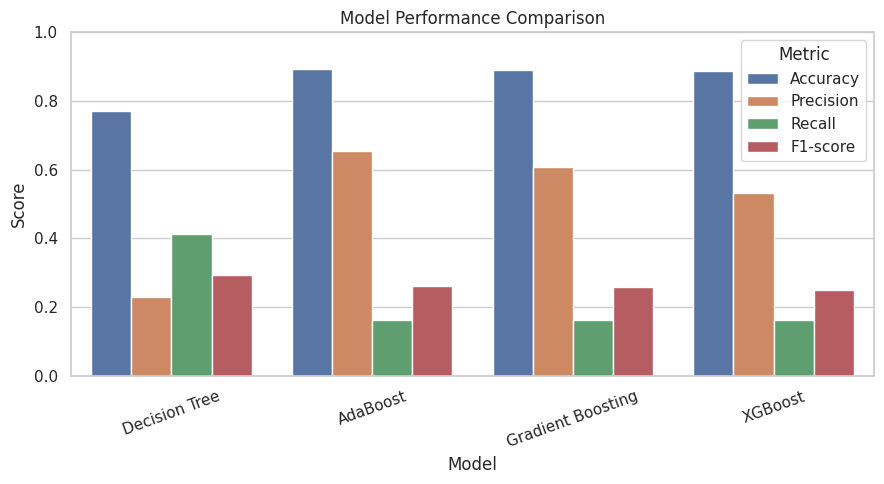

Best model by F1-score: Decision Tree

Classification report:
              precision    recall  f1-score   support

          No       0.91      0.82      0.86       801
         Yes       0.23      0.41      0.29       104

    accuracy                           0.77       905
   macro avg       0.57      0.62      0.58       905
weighted avg       0.84      0.77      0.80       905



In [22]:
plt.figure(figsize=(9,5))
plot_results = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Metric", value_name="Score"
)
sns.barplot(data=plot_results, x="Model", y="Score", hue="Metric")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["Model"]
best_model = pipelines[best_name]
best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print("Best model by F1-score:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No", "Yes"], zero_division=0))

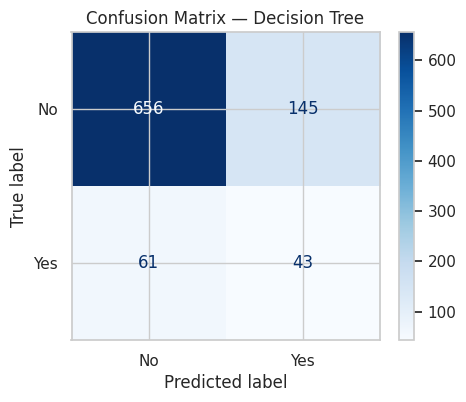

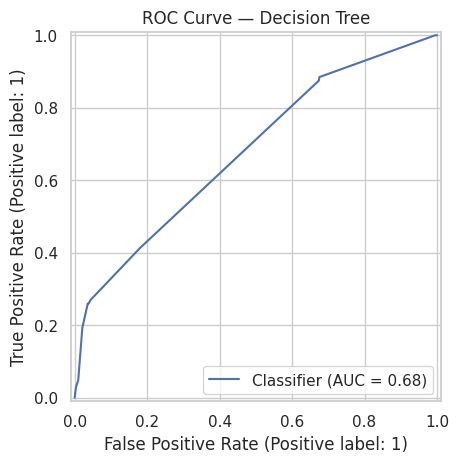

Accuracy : 0.7724
Precision: 0.2287
Recall   : 0.4135
F1-score : 0.2945
ROC-AUC  : 0.6788
PR-AUC   : 0.2508


In [23]:
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["No", "Yes"], cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.show()

RocCurveDisplay.from_predictions(y_test, best_proba)
plt.title(f"ROC Curve — {best_name}")
plt.show()

print("Accuracy :", round(accuracy_score(y_test, best_pred), 4))
print("Precision:", round(precision_score(y_test, best_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, best_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, best_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, best_proba), 4))
print("PR-AUC   :", round(average_precision_score(y_test, best_proba), 4))

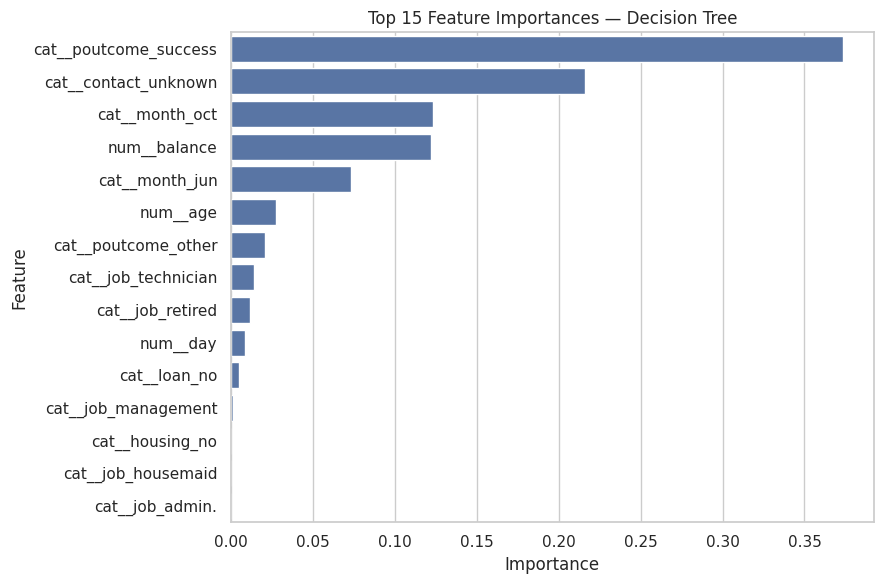

,Feature,Importance
48,cat__poutcome_success,3.737035e-01
33,cat__contact_unknown,2.159721e-01
44,cat__month_oct,1.236028e-01
1,num__balance,1.224879e-01
40,cat__month_jun,7.366938e-02
0,num__age,2.779509e-02
47,cat__poutcome_other,2.110533e-02
15,cat__job_technician,1.404443e-02
11,cat__job_retired,1.184534e-02
2,num__day,8.807817e-03


In [24]:
try:
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_estimator.feature_importances_
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    plt.figure(figsize=(9,6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top 15 Feature Importances — {best_name}")
    plt.tight_layout()
    plt.show()
    display(importance_df)
except Exception as e:
    print("Feature importance could not be displayed for this model:", e)

In [25]:
!pip -q install reportlab

import joblib
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import mm

joblib.dump(best_model, "best_bank_term_deposit_model.joblib")

best_row = results_df.loc[results_df["Model"] == best_name].iloc[0]
report_file = "Bank_Term_Deposit_Project_Report.pdf"

styles = getSampleStyleSheet()
title_style = ParagraphStyle(
    "ReportTitle", parent=styles["Title"], fontSize=16, leading=19,
    textColor=colors.HexColor("#17365D"), spaceAfter=7
)
body_style = ParagraphStyle(
    "ReportBody", parent=styles["BodyText"], fontSize=8.5, leading=11
)
small_style = ParagraphStyle(
    "Small", parent=styles["BodyText"], fontSize=7.5, leading=9
)

doc = SimpleDocTemplate(
    report_file, pagesize=A4,
    rightMargin=16*mm, leftMargin=16*mm,
    topMargin=13*mm, bottomMargin=13*mm
)
story = [
    Paragraph("BANK CUSTOMER TERM DEPOSIT PREDICTION", title_style),
    Paragraph("<b>Using Boosting Algorithms | Google Colab Minor Project</b>", body_style),
    Spacer(1, 5),
    Paragraph(
        "<b>Problem:</b> Predict whether a bank customer will subscribe to a term deposit "
        "based on customer and campaign information. This is a binary classification task.",
        body_style
    ),
    Spacer(1, 5),
    Paragraph(
        "<b>Dataset:</b> Kaggle Bank Marketing competition dataset. The records describe "
        "telephone marketing campaigns of a Portuguese banking institution. The target is "
        "usually named <b>y</b> or <b>deposit</b> (Yes/No).",
        body_style
    ),
    Spacer(1, 5),
    Paragraph(
        "<b>Methodology:</b> CSV loading, duplicate check, target encoding, missing-value "
        "imputation, one-hot encoding, stratified 80:20 train/test split, and comparison of "
        "Decision Tree, AdaBoost, Gradient Boosting and XGBoost.",
        body_style
    ),
    Spacer(1, 5),
    Paragraph(
        "<b>Leakage prevention:</b> The call <i>duration</i> feature is excluded because it is "
        "known only after the call. This report therefore describes a more realistic pre-call prediction.",
        body_style
    ),
    Spacer(1, 7),
    Paragraph("<b>Model comparison (test set)</b>", body_style),
]
table_data = [["Model", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
for _, r in results_df.iterrows():
    table_data.append([
        r["Model"], *[f"{r[c]:.3f}" for c in ["Accuracy","Precision","Recall","F1-score","ROC-AUC"]]
    ])
tbl = Table(table_data, repeatRows=1, colWidths=[39*mm, 23*mm, 23*mm, 20*mm, 20*mm, 22*mm])
tbl.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("FONTNAME", (0,0), (-1,0), "Helvetica-Bold"),
    ("FONTSIZE", (0,0), (-1,-1), 7.5),
    ("GRID", (0,0), (-1,-1), 0.4, colors.HexColor("#B7C9D6")),
    ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#EEF3F8")]),
    ("PADDING", (0,0), (-1,-1), 5),
]))
story += [tbl, Spacer(1, 7)]
story.append(Paragraph(
    f"<b>Best model by F1-score:</b> {best_name}. "
    f"<b>Test metrics:</b> Accuracy {best_row['Accuracy']:.3f}, "
    f"Precision {best_row['Precision']:.3f}, Recall {best_row['Recall']:.3f}, "
    f"F1-score {best_row['F1-score']:.3f}, ROC-AUC {best_row['ROC-AUC']:.3f}.",
    body_style
))
story.append(Spacer(1, 5))
story.append(Paragraph(
    "<b>Conclusion:</b> The model with the highest F1-score on the held-out test set is selected "
    "as the best candidate in this experiment. Precision and recall should be considered together "
    "because the target classes may be imbalanced. Results apply to this dataset and split; they "
    "do not guarantee performance on future campaigns.",
    body_style
))
story.append(Spacer(1, 5))
story.append(Paragraph(
    "<b>Data source and acknowledgement:</b> Kaggle Bank Marketing competition; original data "
    "attributed to S. Moro, P. Cortez and P. Rita (2014), UCI Bank Marketing dataset, "
    "DOI: 10.24432/C5K306. Check the Kaggle competition rules and dataset licence before redistribution.",
    small_style
))
doc.build(story)

print("Saved:", report_file)
print("Saved: best_bank_term_deposit_model.joblib")
files.download(report_file)
files.download("best_bank_term_deposit_model.joblib")

Saved: Bank_Term_Deposit_Project_Report.pdf
Saved: best_bank_term_deposit_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>